<a href="https://colab.research.google.com/github/daisymayorga-galtechs/state-open-data/blob/main/jobs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/qcew-2026-q1.csv')

# Print basic information about the dataset
print(f"Dataset Shape: {df.shape}")
print("\nColumns and Data Types:")
display(df.info())

# Display the first few rows
display(df.head())

Dataset Shape: (56886, 15)

Columns and Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56886 entries, 0 to 56885
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Area Type                   56886 non-null  object 
 1   Area Name                   56886 non-null  object 
 2   Year                        56886 non-null  int64  
 3   Time Period                 56886 non-null  object 
 4   Ownership                   56886 non-null  object 
 5   NAICS Level                 56886 non-null  int64  
 6   NAICS Code                  56886 non-null  object 
 7   Industry Name               56886 non-null  object 
 8   Establishments              56886 non-null  int64  
 9   Average Monthly Employment  56886 non-null  int64  
 10  1st Month Emp               56886 non-null  int64  
 11  2nd Month Emp               56886 non-null  int64  
 12  3rd Month Emp               56886 no

None

,Area Type,Area Name,Year,Time Period,Ownership,NAICS Level,NAICS Code,Industry Name,Establishments,Average Monthly Employment,1st Month Emp,2nd Month Emp,3rd Month Emp,Total Wages (All Workers),Average Weekly Wages
0,County,Alameda County,2026,1st Qtr,Private,5,48411,"General Freight Trucking, Local",411,2085,2104,2110,2041,33508162.0,1236
1,County,Alameda County,2026,1st Qtr,Private,6,484110,"General Freight Trucking, Local",411,2085,2104,2110,2041,33508162.0,1236
2,County,Alameda County,2026,1st Qtr,Private,5,48412,"General Freight Trucking, Long-Distance",255,2137,2212,2113,2087,34234730.0,1232
3,County,Alameda County,2026,1st Qtr,Private,6,484121,"General Freight Trucking, Long-Dist TL",215,1279,1335,1271,1233,20253544.0,1217
4,County,Alameda County,2026,1st Qtr,Private,6,484122,"General Freight Trucking, Long-Dist LTL",40,857,877,842,854,13981186.0,1254


In [2]:
# Sort and aggregate to find significant highlights in the dataset
print("--- Top 5 Counties/Areas by Average Monthly Employment ---")
top_areas = df[df['Area Type'] == 'County'].groupby('Area Name')['Average Monthly Employment'].sum().nlargest(5)
display(top_areas)

print("\n--- Top 5 Industries by Average Monthly Employment (Level 6 NAICS) ---")
top_industries = df[df['NAICS Level'] == 6].groupby('Industry Name')['Average Monthly Employment'].sum().nlargest(5)
display(top_industries)

print("\n--- Top 5 Highest Paying Industries (NAICS Level 6, sorted by Average Weekly Wages) ---")
highest_paying = df[df['NAICS Level'] == 6].sort_values(by='Average Weekly Wages', ascending=False)[['Area Name', 'Industry Name', 'Average Weekly Wages', 'Average Monthly Employment']].head(5)
display(highest_paying)

--- Top 5 Counties/Areas by Average Monthly Employment ---


,Average Monthly Employment
Area Name,
Los Angeles County,40688376
Orange County,14777208
San Diego County,13677991
Santa Clara County,9815776
Riverside County,7535174



--- Top 5 Industries by Average Monthly Employment (Level 6 NAICS) ---


,Average Monthly Employment
Industry Name,
Elementary and Secondary Schools,10951501
General Medical and Surgical Hospitals,7667318
Full-Service Restaurants,6402298
Limited-service restaurants,5635252
Services for the Elderly and Disabled,4659631



--- Top 5 Highest Paying Industries (NAICS Level 6, sorted by Average Weekly Wages) ---


,Area Name,Industry Name,Average Weekly Wages,Average Monthly Employment
36998,San Luis Obispo County,Interurban and Rural Bus Transportation,75416,2
6507,Colusa County,Legislative Bodies,37555,2
38429,San Mateo County,Investment Banking and Securities Intermediation,30429,1119
34676,San Francisco County,Investment Banking and Securities Intermediation,20763,6283
41097,Santa Clara County,"Lessors, Nonfinancial Intangible Assets",20713,319


In [3]:
# Filter dataset for Stanislaus County
stanislaus_df = df[df['Area Name'] == 'Stanislaus County']

# Calculate total establishments and average monthly employment in the county
print(f"--- Stanislaus County Overview ---")
total_establishments = stanislaus_df[stanislaus_df['NAICS Level'] == 2]['Establishments'].sum()
total_employment = stanislaus_df[stanislaus_df['NAICS Level'] == 2]['Average Monthly Employment'].sum()
print(f"Total Establishments (Level 2 sectors): {total_establishments}")
print(f"Average Monthly Employment (Level 2 sectors): {total_employment}\n")

# Top industries by employment in Stanislaus County
print("--- Top 5 Industries in Stanislaus County by Employment (NAICS Level 6) ---")
top_emp_stanislaus = stanislaus_df[stanislaus_df['NAICS Level'] == 6].groupby('Industry Name')['Average Monthly Employment'].sum().nlargest(5)
display(top_emp_stanislaus)

# Highest paying industries in Stanislaus County
print("\n--- Top 5 Highest Paying Industries in Stanislaus County (NAICS Level 6) ---")
top_pay_stanislaus = stanislaus_df[stanislaus_df['NAICS Level'] == 6].sort_values(by='Average Weekly Wages', ascending=False)[['Industry Name', 'Average Weekly Wages', 'Average Monthly Employment']].head(5)
display(top_pay_stanislaus)

--- Stanislaus County Overview ---
Total Establishments (Level 2 sectors): 34775
Average Monthly Employment (Level 2 sectors): 371987

--- Top 5 Industries in Stanislaus County by Employment (NAICS Level 6) ---


,Average Monthly Employment
Industry Name,
Elementary and Secondary Schools,19930
Services for the Elderly and Disabled,9058
Limited-service restaurants,7525
Full-Service Restaurants,5850
Supermarkets and Other Grocery Stores,4107



--- Top 5 Highest Paying Industries in Stanislaus County (NAICS Level 6) ---


,Industry Name,Average Weekly Wages,Average Monthly Employment
47150,Investment Banking and Securities Intermediation,6842,98
47262,HMO Medical Centers,3777,3535
47414,Executive Offices,3399,8
47731,All Other Plastics Product Manufacturing,3239,391
47142,Portfolio Management and Investment Advice,3228,123


In [4]:
# Get all unique industry names from the dataset, sorted alphabetically
unique_industries = sorted(df['Industry Name'].unique())

print(f"Total unique industries found: {len(unique_industries)}")
print("\nFirst 50 industries:")
display(unique_industries[:50])

# Set variable for full list access
all_industries_list = unique_industries

Total unique industries found: 1507

First 50 industries:


['AC, Refrigeration, & Forced Air Heating',
 'Abrasive Product Manufacturing',
 'Accessories and Other Apparel Mfg',
 'Accommodation',
 'Accommodation and Food Services',
 'Accounting and Bookkeeping Services',
 'Activities Rel to Credit Intermediation',
 'Activities Related to Real Estate',
 'Adhesive Manufacturing',
 'Administration of Conservation Programs',
 'Administration of Economic Programs',
 'Administration of Education Programs',
 'Administration of Environmental Programs',
 'Administration of General Economic Prog',
 'Administration of Housing Programs',
 'Administration of Human Resource Program',
 'Administration of Public Health Programs',
 "Administration of Veterans' Affairs",
 'Administrative Management Consulting Svc',
 'Administrative and Support Services',
 'Administrative and Waste Services',
 'Advertising Agencies',
 'Advertising Material Distribution Svc',
 'Advertising and Related Services',
 'Aerospace Product & Parts Manufacturing',
 'Ag., Construction, and M

In [5]:
# Check if there are columns related to business size class, or analyze the distribution of employees per establishment
print("Columns in dataset:")
print(df.columns.tolist())

# Let's filter Stanislaus County private sector records at a detailed NAICS level (e.g., Level 6)
# and calculate the average employment per establishment as an indicator.
stanislaus_detailed = df[(df['Area Name'] == 'Stanislaus County') & (df['NAICS Level'] == 6) & (df['Ownership'] == 'Private')]

# Calculate basic statistics on employment per establishment
stanislaus_detailed['Emp_Per_Establishment'] = stanislaus_detailed['Average Monthly Employment'] / stanislaus_detailed['Establishments']
print("\nAverage employment per establishment across detailed private industries in Stanislaus County:")
display(stanislaus_detailed[['Industry Name', 'Establishments', 'Average Monthly Employment', 'Emp_Per_Establishment']].describe())

Columns in dataset:
['Area Type', 'Area Name', 'Year', 'Time Period', 'Ownership', 'NAICS Level', 'NAICS Code', 'Industry Name', 'Establishments', 'Average Monthly Employment', '1st Month Emp', '2nd Month Emp', '3rd Month Emp', 'Total Wages (All Workers)', 'Average Weekly Wages']

Average employment per establishment across detailed private industries in Stanislaus County:


/tmp/ipykernel_2189/2660179537.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  stanislaus_detailed['Emp_Per_Establishment'] = stanislaus_detailed['Average Monthly Employment'] / stanislaus_detailed['Establishments']


,Establishments,Average Monthly Employment,Emp_Per_Establishment
count,302.000000,302.000000,302.000000
mean,55.880795,425.986755,16.771071
std,402.254460,900.751963,32.867243
min,3.000000,5.000000,1.000000
25%,8.000000,57.250000,4.360440
50%,15.000000,152.500000,8.000000
75%,35.000000,388.000000,16.000000
max,6965.000000,8471.000000,267.500000


In [6]:
# Calculate total employment for industries with small average establishment sizes in Stanislaus County (Private Sector, detailed Level 6 NAICS)

# Under 20 employees (Very small businesses/Micro-businesses average)
small_biz_20 = stanislaus_detailed[stanislaus_detailed['Emp_Per_Establishment'] < 20]
total_emp_20 = small_biz_20['Average Monthly Employment'].sum()
total_est_20 = small_biz_20['Establishments'].sum()

# Under 50 employees (Small businesses average)
small_biz_50 = stanislaus_detailed[stanislaus_detailed['Emp_Per_Establishment'] < 50]
total_emp_50 = small_biz_50['Average Monthly Employment'].sum()
total_est_50 = small_biz_50['Establishments'].sum()

print(f"For industries averaging fewer than 20 employees per establishment:")
print(f"- Total Establishments: {total_est_20}")
print(f"- Total Employees: {total_emp_20}")

print(f"\nFor industries averaging fewer than 50 employees per establishment:")
print(f"- Total Establishments: {total_est_50}")
print(f"- Total Employees: {total_emp_50}")

For industries averaging fewer than 20 employees per establishment:
- Total Establishments: 15839
- Total Employees: 81004

For industries averaging fewer than 50 employees per establishment:
- Total Establishments: 16622
- Total Employees: 103892


In [7]:
# Find top 10 industries by average monthly employment for the < 20 employee bucket
top_10_small_biz_20 = small_biz_20.groupby('Industry Name')['Average Monthly Employment'].sum().nlargest(10).reset_index()

# Find top 10 industries by average monthly employment for the < 50 employee bucket
top_10_small_biz_50 = small_biz_50.groupby('Industry Name')['Average Monthly Employment'].sum().nlargest(10).reset_index()

print("=== Top 10 Industries in Stanislaus County for < 20 Employees/Establishment ===")
display(top_10_small_biz_20)

print("\n=== Top 10 Industries in Stanislaus County for < 50 Employees/Establishment ===")
display(top_10_small_biz_50)

=== Top 10 Industries in Stanislaus County for < 20 Employees/Establishment ===


,Industry Name,Average Monthly Employment
0,Services for the Elderly and Disabled,8471
1,Limited-service restaurants,7525
2,Full-Service Restaurants,5850
3,"Offices of Physicians, ex. Mental Health",3513
4,Snack and nonalcoholic beverage bars,2253
5,Offices of Dentists,1982
6,Tree Nut Farming,1529
7,Dairy Cattle and Milk Production,1482
8,Homes for the Elderly,1141
9,Clothing and Clothing Accessories Retailers,1114



=== Top 10 Industries in Stanislaus County for < 50 Employees/Establishment ===


,Industry Name,Average Monthly Employment
0,Services for the Elderly and Disabled,8471
1,Limited-service restaurants,7525
2,Full-Service Restaurants,5850
3,Supermarkets and Other Grocery Stores,4107
4,"Offices of Physicians, ex. Mental Health",3513
5,Snack and nonalcoholic beverage bars,2253
6,Farm Labor Contractors and Crew Leaders,2076
7,Offices of Dentists,1982
8,Home Health Care Services,1667
9,Tree Nut Farming,1529


### Job Market Analysis for Job Seekers in Stanislaus County
To help you target your job search, let's look at the data from two angles:
1. **High-Volume Industries:** Sectors that employ the largest number of people in the county (providing the most job openings).
2. **High-Paying Industries:** Sectors offering the highest weekly wages.

In [8]:
# 1. Top High-Volume Industries in Stanislaus County (across all ownership types at Level 6)
top_volume_stanislaus = stanislaus_df[stanislaus_df['NAICS Level'] == 6].groupby('Industry Name').agg(
    Total_Employment=('Average Monthly Employment', 'sum'),
    Average_Weekly_Wage=('Average Weekly Wages', 'mean'),
    Establishments=('Establishments', 'sum')
).nlargest(10, 'Total_Employment').reset_index()

print("=== TOP 10 HIGH-VOLUME INDUSTRIES IN STANISLAUS COUNTY ===")
display(top_volume_stanislaus)

=== TOP 10 HIGH-VOLUME INDUSTRIES IN STANISLAUS COUNTY ===


,Industry Name,Total_Employment,Average_Weekly_Wage,Establishments
0,Elementary and Secondary Schools,19930,1015.0,206
1,Services for the Elderly and Disabled,9058,925.5,6966
2,Limited-service restaurants,7525,512.0,455
3,Full-Service Restaurants,5850,572.0,321
4,Supermarkets and Other Grocery Stores,4107,769.0,136
5,General Warehousing and Storage,3847,1545.0,36
6,HMO Medical Centers,3535,3777.0,14
7,"Offices of Physicians, ex. Mental Health",3515,2065.0,325
8,Temporary Help Services,2452,708.0,45
9,Warehouse Clubs and Supercenters,2383,832.0,9


In [9]:
# 2. Top High-Paying Industries in Stanislaus County (employing at least 100 people to filter out tiny outliers)
top_paying_stanislaus = stanislaus_df[
    (stanislaus_df['NAICS Level'] == 6) &
    (stanislaus_df['Average Monthly Employment'] >= 100)
].groupby('Industry Name').agg(
    Average_Weekly_Wage=('Average Weekly Wages', 'max'),
    Total_Employment=('Average Monthly Employment', 'sum')
).nlargest(10, 'Average_Weekly_Wage').reset_index()

print("=== TOP 10 HIGH-PAYING INDUSTRIES IN STANISLAUS COUNTY (with 100+ Employees) ===")
display(top_paying_stanislaus)

=== TOP 10 HIGH-PAYING INDUSTRIES IN STANISLAUS COUNTY (with 100+ Employees) ===


,Industry Name,Average_Weekly_Wage,Total_Employment
0,HMO Medical Centers,3777,3535
1,All Other Plastics Product Manufacturing,3239,391
2,Portfolio Management and Investment Advice,3228,123
3,Real Estate Credit,2993,101
4,Managing Offices,2980,1114
5,"Offices of Physicians, ex. Mental Health",2775,3513
6,Other Justice and Safety Activities,2752,703
7,Electric Bulk Power Transmission,2709,710
8,Custom Computer Programming Services,2507,110
9,Other Nonresidential Equipment Contrs,2286,185


### Bay Area Counties Small Business and Job Market Analysis
Let's define the 9 traditional Bay Area counties in our dataset and perform the same analysis for small businesses (< 20 and < 50 employees) as well as general top-paying/high-volume jobs.

In [10]:
# Define Bay Area Counties
bay_area_counties = [
    'Alameda County', 'Contra Costa County', 'Marin County', 'Napa County',
    'San Francisco County', 'San Mateo County', 'Santa Clara County',
    'Solano County', 'Sonoma County'
]

# Filter dataset for Bay Area
bay_df = df[df['Area Name'].isin(bay_area_counties)]

# Filter private sector records at Level 6 NAICS
bay_detailed = bay_df[(bay_df['NAICS Level'] == 6) & (bay_df['Ownership'] == 'Private')].copy()
bay_detailed['Emp_Per_Establishment'] = bay_detailed['Average Monthly Employment'] / bay_detailed['Establishments']

# Under 20 employees (Micro-businesses)
bay_small_biz_20 = bay_detailed[bay_detailed['Emp_Per_Establishment'] < 20]

# Under 50 employees (Small businesses)
bay_small_biz_50 = bay_detailed[bay_detailed['Emp_Per_Establishment'] < 50]

# Get Top 10 Industries for both buckets
bay_top_10_small_biz_20 = bay_small_biz_20.groupby('Industry Name')['Average Monthly Employment'].sum().nlargest(10).reset_index()
bay_top_10_small_biz_50 = bay_small_biz_50.groupby('Industry Name')['Average Monthly Employment'].sum().nlargest(10).reset_index()

print("=== Bay Area Top 10 Industries for < 20 Employees/Establishment ===")
display(bay_top_10_small_biz_20)

print("\n=== Bay Area Top 10 Industries for < 50 Employees/Establishment ===")
display(bay_top_10_small_biz_50)

=== Bay Area Top 10 Industries for < 20 Employees/Establishment ===


,Industry Name,Average Monthly Employment
0,Services for the Elderly and Disabled,176040
1,Full-Service Restaurants,126766
2,Custom Computer Programming Services,109243
3,Limited-service restaurants,90737
4,"Offices of Physicians, ex. Mental Health",42360
5,Offices of Dentists,31682
6,Offices of Lawyers,31470
7,Snack and nonalcoholic beverage bars,28886
8,Janatorial Services,27248
9,Child Day Care Services,26128



=== Bay Area Top 10 Industries for < 50 Employees/Establishment ===


,Industry Name,Average Monthly Employment
0,Services for the Elderly and Disabled,176040
1,Full-Service Restaurants,130579
2,Custom Computer Programming Services,109243
3,Limited-service restaurants,90737
4,Software Publishers,68365
5,Supermarkets and Other Grocery Stores,62287
6,Computer Systems Design Services,53312
7,Data Processing and Related Services,48421
8,"Offices of Physicians, ex. Mental Health",42360
9,"Research and Dvlpmt in PS, ES, and Life Sci (e...",39855


In [11]:
# Top 10 High-Paying Industries in the Bay Area (with 500+ employees to keep it statistically robust for this larger region)
bay_top_paying = bay_df[
    (bay_df['NAICS Level'] == 6) &
    (bay_df['Average Monthly Employment'] >= 500)
].groupby('Industry Name').agg(
    Average_Weekly_Wage=('Average Weekly Wages', 'max'),
    Total_Employment=('Average Monthly Employment', 'sum')
).nlargest(10, 'Average_Weekly_Wage').reset_index()

print("=== TOP 10 HIGH-PAYING INDUSTRIES IN THE BAY AREA (500+ Employees) ===")
display(bay_top_paying)

=== TOP 10 HIGH-PAYING INDUSTRIES IN THE BAY AREA (500+ Employees) ===


,Industry Name,Average_Weekly_Wage,Total_Employment
0,Investment Banking and Securities Intermediation,30429,10077
1,Semiconductor and Related Devices,17275,35094
2,Portfolio Management and Investment Advice,17207,19027
3,Semiconductor Machinery Manufacturing,15269,12141
4,All Other Travel Arrangement Services,13833,2747
5,All Other Telecommunications,13718,2500
6,Web Search Portals and All Other Information S...,13452,9895
7,"Media streaming distribution services, social ...",13286,17844
8,"Research and Dvlpmt in PS, ES, and Life Sci (e...",11666,58034
9,Druggists' Goods Merchant Wholesalers,11458,3651


In [12]:
# Filter dataset for Custom Computer Programming Services in Stanislaus County
stanislaus_tech = df[
    (df['Area Name'] == 'Stanislaus County') &
    (df['Industry Name'] == 'Custom Computer Programming Services')
]

print("=== Custom Computer Programming Services in Stanislaus County ===")
display(stanislaus_tech[['Area Name', 'Ownership', 'Establishments', 'Average Monthly Employment', 'Average Weekly Wages']])

=== Custom Computer Programming Services in Stanislaus County ===


,Area Name,Ownership,Establishments,Average Monthly Employment,Average Weekly Wages
47070,Stanislaus County,Private,31,110,2507


In [13]:
# Identify unique tech-related industries in the dataset to filter them precisely
tech_keywords = ['computer', 'software', 'programming', 'data processing', 'information services', 'scientific research', 'semiconductor', 'web search', 'internet']

# Filter Stanislaus County Level 6 NAICS private sector records matching our keywords
stanislaus_tech_all = stanislaus_df[
    (stanislaus_df['NAICS Level'] == 6) &
    (stanislaus_df['Ownership'] == 'Private') &
    (stanislaus_df['Industry Name'].str.contains('|'.join(tech_keywords), case=False, na=False))
]

# Print detailed list of identified tech industries
print("=== Detailed Tech-Related Industries in Stanislaus County ===")
display(stanislaus_tech_all[['Industry Name', 'Establishments', 'Average Monthly Employment', 'Average Weekly Wages']])

# Calculate totals
total_tech_establishments = stanislaus_tech_all['Establishments'].sum()
total_tech_employment = stanislaus_tech_all['Average Monthly Employment'].sum()
weighted_avg_wage = (stanislaus_tech_all['Average Weekly Wages'] * stanislaus_tech_all['Average Monthly Employment']).sum() / total_tech_employment if total_tech_employment > 0 else 0

print(f"\n=== TOTAL TECH-RELATED SECTOR SUMMARY FOR STANISLAUS COUNTY ===")
print(f"Total Tech Establishments: {total_tech_establishments}")
print(f"Total Tech Employment: {total_tech_employment} jobs")
print(f"Weighted Average Weekly Wage: ${weighted_avg_wage:.2f} (Est. ${weighted_avg_wage * 52:.2f}/year)")

=== Detailed Tech-Related Industries in Stanislaus County ===


,Industry Name,Establishments,Average Monthly Employment,Average Weekly Wages
47028,Software Publishers,7,20,2875
47069,Computer Systems Design Services,28,108,1625
47070,Custom Computer Programming Services,31,110,2507



=== TOTAL TECH-RELATED SECTOR SUMMARY FOR STANISLAUS COUNTY ===
Total Tech Establishments: 66
Total Tech Employment: 238 jobs
Weighted Average Weekly Wage: $2137.69 (Est. $111159.83/year)


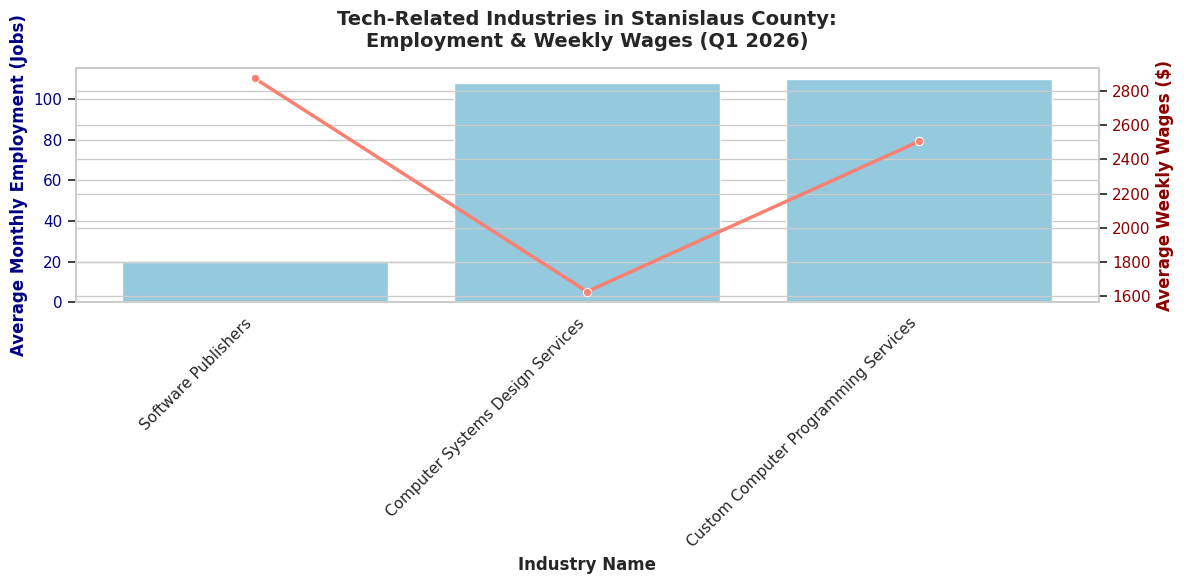

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure plot style
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Average Monthly Employment on the left axis
color = 'skyblue'
ax1.set_xlabel('Industry Name', fontweight='bold')
ax1.set_ylabel('Average Monthly Employment (Jobs)', color='navy', fontweight='bold')
sns.barplot(data=stanislaus_tech_all, x='Industry Name', y='Average Monthly Employment', ax=ax1, color=color)
ax1.tick_params(axis='y', labelcolor='navy')

# Explicitly set ticks and then set labels to avoid UserWarning
ax1.set_xticks(range(len(stanislaus_tech_all)))
ax1.set_xticklabels(stanislaus_tech_all['Industry Name'], rotation=45, ha='right')

# Create a second y-axis for Average Weekly Wages
ax2 = ax1.twinx()
color = 'salmon'
ax2.set_ylabel('Average Weekly Wages ($)', color='darkred', fontweight='bold')
sns.lineplot(data=stanislaus_tech_all, x='Industry Name', y='Average Weekly Wages', ax=ax2, color=color, marker='o', linewidth=2.5, sort=False)
ax2.tick_params(axis='y', labelcolor='darkred')

plt.title('Tech-Related Industries in Stanislaus County:\nEmployment & Weekly Wages (Q1 2026)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

/tmp/ipykernel_2189/263326516.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')


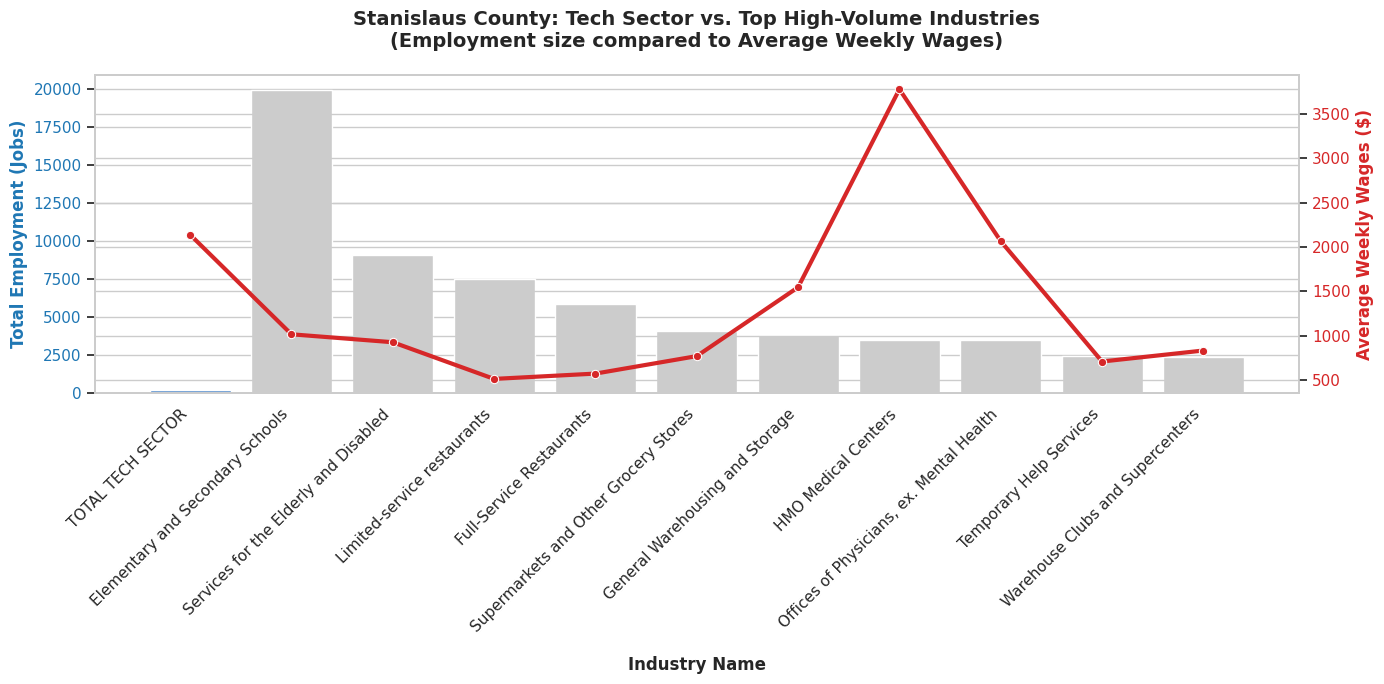

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare tech data for aggregation to represent as a single 'Tech Sector' category
total_tech_emp = stanislaus_tech_all['Average Monthly Employment'].sum()
total_tech_establishments = stanislaus_tech_all['Establishments'].sum()
weighted_tech_wage = (stanislaus_tech_all['Average Weekly Wages'] * stanislaus_tech_all['Average Monthly Employment']).sum() / total_tech_emp if total_tech_emp > 0 else 0

# Create a DataFrame for the comparison
tech_summary_df = pd.DataFrame([{
    'Industry Name': 'TOTAL TECH SECTOR',
    'Total_Employment': total_tech_emp,
    'Average_Weekly_Wage': weighted_tech_wage,
    'Establishments': total_tech_establishments
}])

# Combine the top volume industries with our tech summary
comparison_df = pd.concat([tech_summary_df, top_volume_stanislaus], ignore_index=True)

# Plotting the comparison
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(14, 7))

# Colors to highlight the Tech Sector
colors = ['#4A90E2' if name == 'TOTAL TECH SECTOR' else '#CCCCCC' for name in comparison_df['Industry Name']]

# Barplot for Employment
ax1.set_xlabel('Industry Name', fontweight='bold', labelpad=15)
ax1.set_ylabel('Total Employment (Jobs)', color='#1f77b4', fontweight='bold')
sns.barplot(data=comparison_df, x='Industry Name', y='Total_Employment', ax=ax1, palette=colors, hue='Industry Name', legend=False)
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')

# Lineplot for Wages
ax2 = ax1.twinx()
ax2.set_ylabel('Average Weekly Wages ($)', color='#d62728', fontweight='bold')
sns.lineplot(data=comparison_df, x='Industry Name', y='Average_Weekly_Wage', ax=ax2, color='#d62728', marker='o', linewidth=3, sort=False)
ax2.tick_params(axis='y', labelcolor='#d62728')

plt.title('Stanislaus County: Tech Sector vs. Top High-Volume Industries\n(Employment size compared to Average Weekly Wages)', fontsize=14, fontweight='bold', pad=20)
fig.tight_layout()
plt.show()

In [16]:
# Filter for Stanislaus County at NAICS Level 0 (Total, All Industries)
stan_summary = df[
    (df['Area Name'] == 'Stanislaus County') &
    (df['NAICS Level'] == 0)
][['Ownership', 'Establishments', 'Average Monthly Employment', 'Average Weekly Wages']]

# Order rows logically: Private, Local, State, Federal, then Total Covered
ownership_order = ['Private', 'Local Government', 'State Government', 'Federal Government', 'Total Covered']
stan_summary['Ownership'] = pd.Categorical(stan_summary['Ownership'], categories=ownership_order, ordered=True)
stan_summary = stan_summary.sort_values('Ownership').reset_index(drop=True)

# Format numbers with commas for display
formatted_table = stan_summary.copy()
formatted_table['Establishments'] = formatted_table['Establishments'].apply(lambda x: f"{x:,.0f}")
formatted_table['Average Monthly Employment'] = formatted_table['Average Monthly Employment'].apply(lambda x: f"{x:,.0f}")
formatted_table['Average Weekly Wages'] = formatted_table['Average Weekly Wages'].apply(lambda x: f"${x:,.0f}")

display(formatted_table)

,Ownership,Establishments,Average Monthly Employment,Average Weekly Wages
0,Private,"18,398","161,676","$1,229"
1,Local Government,304,"31,216","$1,427"
2,State Government,75,"1,868","$1,432"
3,Federal Government,35,709,"$1,741"
4,Total Covered,"18,812","195,471","$1,265"


In [19]:
stan = df[df['Area Name'] == 'Stanislaus County']

# Get Level 0 totals
totals = stan[stan['NAICS Level'] == 0].set_index('Ownership')
total_jobs = totals.loc['Total Covered', 'Average Monthly Employment']
total_est = totals.loc['Total Covered', 'Establishments']

print(f"STANISLAUS COUNTY TOTAL COVERED EMPLOYMENT: {total_jobs:,} jobs ({total_est:,} establishments)")
print("=" * 85)

ownership_types = ['Local Government', 'State Government', 'Federal Government', 'Private']

for own in ownership_types:
    emp = totals.loc[own, 'Average Monthly Employment']
    est = totals.loc[own, 'Establishments']
    wage = totals.loc[own, 'Average Weekly Wages']

    print(f"\n├── [{own.upper()}] — {emp:,} jobs | {est:,} establishments | avg ${wage:,}/week")

    # Filter 6-digit detailed industries under this ownership
    sub = stan[(stan['Ownership'] == own) & (stan['NAICS Level'] == 6)].sort_values(
        by='Average Monthly Employment', ascending=False
    )

    # Set display limit (governments show all/top 10, private shows top 12)
    top_n = 12 if own == 'Private' else 10
    displayed_rows = sub.head(top_n)

    for i, (_, row) in enumerate(displayed_rows.iterrows()):
        is_last = (i == len(displayed_rows) - 1) and (len(sub) <= top_n)
        branch = "└── " if is_last else "├── "
        print(f"│   {branch}{row['Industry Name']} ({row['NAICS Code']}): "
              f"{row['Average Monthly Employment']:,} jobs across {row['Establishments']:,} locations "
              f"(avg ${row['Average Weekly Wages']:,}/wk)")

    if len(sub) > top_n:
        remaining_emp = sub.iloc[top_n:]['Average Monthly Employment'].sum()
        remaining_est = sub.iloc[top_n:]['Establishments'].sum()
        print(f"│   └── ... and {len(sub) - top_n} other detailed industries ({remaining_emp:,} jobs across {remaining_est:,} locations)")

STANISLAUS COUNTY TOTAL COVERED EMPLOYMENT: 195,471 jobs (18,812 establishments)

├── [LOCAL GOVERNMENT] — 31,216 jobs | 304 establishments | avg $1,427/week
│   ├── Elementary and Secondary Schools (611110): 19,540 jobs across 194 locations (avg $1,230/wk)
│   ├── Executive & Legislative Offices Combined (921140): 1,355 jobs across 14 locations (avg $1,663/wk)
│   ├── Junior Colleges (611210): 1,170 jobs across 2 locations (avg $1,988/wk)
│   ├── Other Individual and Family Services (624190): 954 jobs across 1 locations (avg $1,336/wk)
│   ├── Police Protection (922120): 883 jobs across 1 locations (avg $2,152/wk)
│   ├── Electric Bulk Power Transmission (221121): 710 jobs across 3 locations (avg $2,709/wk)
│   ├── Other Justice and Safety Activities (922190): 703 jobs across 3 locations (avg $2,752/wk)
│   ├── Services for the Elderly and Disabled (624120): 587 jobs across 1 locations (avg $1,419/wk)
│   ├── General Medical and Surgical Hospitals (622110): 516 jobs across 1 locations

In [20]:
# --- 2. DETAILED SUBSECTOR BREAKDOWN (Level 3) ---
subsectors = stan[
    (stan['Ownership'] == 'Private')
    & (stan['NAICS Level'] == 3)
    & (
        stan['NAICS Code'].str.startswith(
            ('31', '32', '33', '42', '48', '49')
        )  # Manufacturing, Wholesale, Transportation
    )
][
    [
        'NAICS Code',
        'Industry Name',
        'Establishments',
        'Average Monthly Employment',
        'Average Weekly Wages',
    ]
].sort_values(by='Average Monthly Employment', ascending=False)

display(subsectors.reset_index(drop=True))

,NAICS Code,Industry Name,Establishments,Average Monthly Employment,Average Weekly Wages
0,311,Food Manufacturing,147,9840,1366
1,493,Warehousing and Storage,48,4074,1137
2,312,Beverage & Tobacco Product Manufacturing,16,2898,2311
3,424,"Merchant Wholesalers, Nondurable Goods",164,2788,1503
4,423,"Merchant Wholesalers, Durable Goods",219,2584,1624
5,484,Truck Transportation,509,2421,1293
6,332,Fabricated Metal Product Manufacturing,95,1829,1592
7,322,Paper Manufacturing,11,1245,1842
8,485,Transit and Ground Passenger Transport,18,1023,1006
9,327,Nonmetallic Mineral Product Mfg,15,833,2049


In [21]:
# Clean whitespace from string columns
df['NAICS Code'] = df['NAICS Code'].astype(str).str.strip()
df['Industry Name'] = df['Industry Name'].astype(str).str.strip()

# Target the 5 industries
target_industries = [
    'Health Care and Social Assistance',
    'Retail Trade',
    'Manufacturing',
    'Accommodation and Food Services',
    'Construction',
]

# Filter for Stanislaus County, Private ownership, Level 2, excluding 1000-series domain codes
top5_sectors = (
    df[
        (df['Area Name'] == 'Stanislaus County')
        & (df['Ownership'] == 'Private')
        & (df['NAICS Level'] == 2)
        & (df['Industry Name'].isin(target_industries))
        & (~df['NAICS Code'].str.startswith('10'))
    ][
        [
            'NAICS Code',
            'Industry Name',
            'Average Monthly Employment',
            'Establishments',
            'Average Weekly Wages',
        ]
    ]
    .sort_values(by='Average Monthly Employment', ascending=False)
    .reset_index(drop=True)
)

# Print in the requested format
for i, row in top5_sectors.iterrows():
    print(
        f"{i+1}. {row['Industry Name']} ({row['NAICS Code']}): {row['Average Monthly Employment']:,} jobs"
    )

# Display full table
display(top5_sectors)

1. Health Care and Social Assistance (62): 38,082 jobs
2. Retail Trade (44-45): 22,182 jobs
3. Manufacturing (31-33): 20,765 jobs
4. Accommodation and Food Services (72): 17,271 jobs
5. Construction (23): 10,599 jobs


,NAICS Code,Industry Name,Average Monthly Employment,Establishments,Average Weekly Wages
0,62,Health Care and Social Assistance,38082,8268,1522
1,44-45,Retail Trade,22182,1480,835
2,31-33,Manufacturing,20765,498,1617
3,72,Accommodation and Food Services,17271,1111,543
4,23,Construction,10599,1209,1440


In [22]:
# Clean string columns
df['NAICS Code'] = df['NAICS Code'].astype(str).str.strip()
df['Industry Name'] = df['Industry Name'].astype(str).str.strip()

# Filter for Stanislaus County, Private ownership, Level 2 (excluding BLS 1000-series)
top10_private_level2 = (
    df[
        (df['Area Name'] == 'Stanislaus County')
        & (df['Ownership'] == 'Private')
        & (df['NAICS Level'] == 2)
        & (~df['NAICS Code'].str.startswith('10'))
    ][
        [
            'NAICS Code',
            'Industry Name',
            'Average Monthly Employment',
            'Establishments',
            'Average Weekly Wages',
        ]
    ]
    .sort_values(by='Average Monthly Employment', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Display formatted table
display(top10_private_level2)

,NAICS Code,Industry Name,Average Monthly Employment,Establishments,Average Weekly Wages
0,62,Health Care and Social Assistance,38082,8268,1522
1,44-45,Retail Trade,22182,1480,835
2,31-33,Manufacturing,20765,498,1617
3,72,Accommodation and Food Services,17271,1111,543
4,23,Construction,10599,1209,1440
5,48-49,Transportation and Warehousing,8694,688,1159
6,56,Administrative and Waste Services,7119,563,943
7,54,Professional and Technical Services,5783,805,1413
8,42,Wholesale Trade,5476,411,1570
9,81,"Other Services, Ex. Public Admin",4962,969,866
